# Importing Required Packages of various categories like for Analysis, Visualization and Model Building etc...

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from numpy import mean
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, RandomForestRegressor, GradientBoostingRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import f1_score, confusion_matrix, recall_score, precision_score, classification_report
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression
import warnings
warnings.filterwarnings('ignore')

# Loading Dataset

In [2]:
df = pd.read_csv('/Users/abhimanyu_yadav/Desktop/Practice/HotelBooking/hotel_bookings.csv')

In [3]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


# Checking Shapes of entire data

In [4]:
df.shape

(119390, 32)

In [5]:
df.dtypes

hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
assigned_room_type                 object
booking_changes                     int64
deposit_type                       object
agent                             

# Checking missing values and missing percentage

In [6]:
missing = df.isnull().sum()
miss_per = (missing/df.shape[0])*100
dic = {'No. of Missing value': missing, 'Missing percentage': miss_per}
dic = pd.DataFrame(dic)
dic

,No. of Missing value,Missing percentage
hotel,0,0.000000
is_canceled,0,0.000000
lead_time,0,0.000000
arrival_date_year,0,0.000000
arrival_date_month,0,0.000000
arrival_date_week_number,0,0.000000
arrival_date_day_of_month,0,0.000000
stays_in_weekend_nights,0,0.000000
stays_in_week_nights,0,0.000000
adults,0,0.000000


In [7]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [8]:
df['is_canceled'].value_counts()

0    75166
1    44224
Name: is_canceled, dtype: int64

In [9]:
df['hotel'].value_counts()

City Hotel      79330
Resort Hotel    40060
Name: hotel, dtype: int64

In [10]:
df['target'] = np.where(df['is_canceled'].isin([1]),1,0)
df.drop(['is_canceled'], axis=1, inplace=True)

In [11]:
print("Percentage cancelation =", df['target'].mean())

Percentage cancelation = 0.37041628277075134


# Graphical Analysis

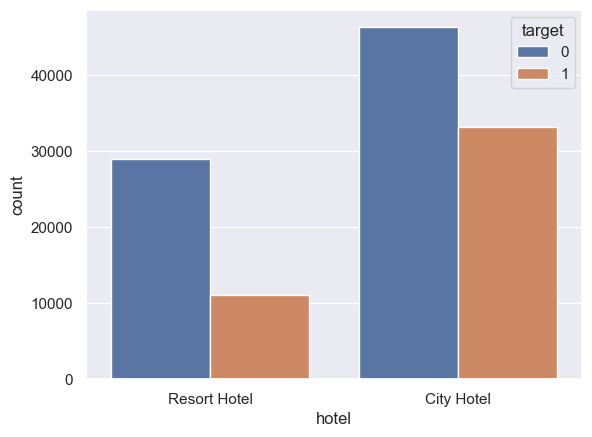

City hotels have higher cancelation rate than resort hotels.


In [12]:
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.countplot(data=df, x='hotel', hue='target')
plt.show()
print('City hotels have higher cancelation rate than resort hotels.')

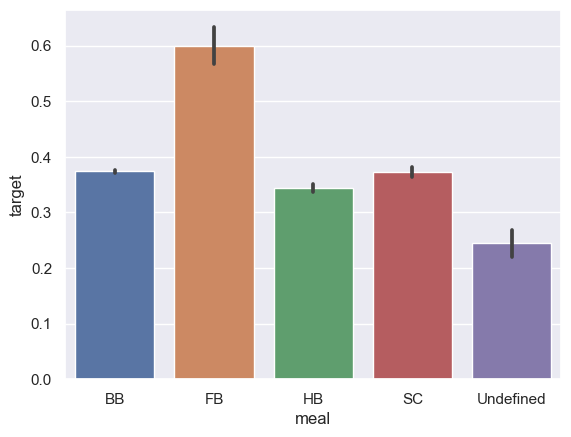

In [13]:
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.barplot(data=df, x='meal', y= 'target', estimator=mean)
plt.show()

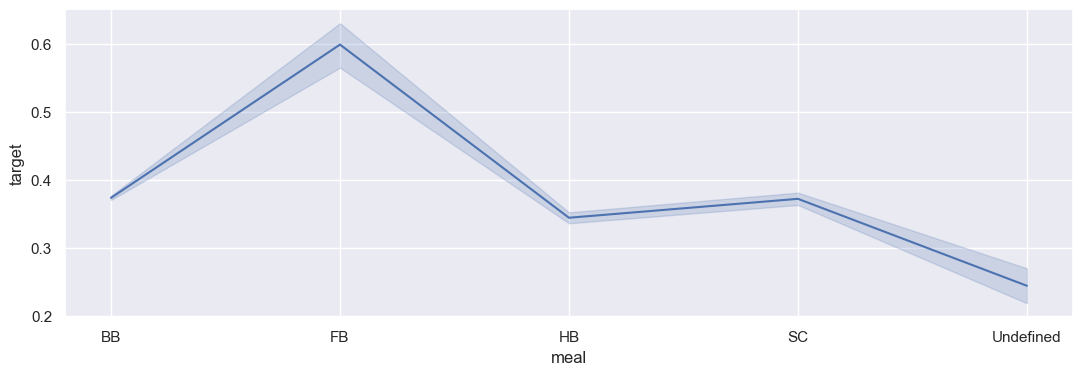

In [14]:
plt.figure(figsize=(13,4))
sns.lineplot(x="meal", y="target", data=df)
plt.show()

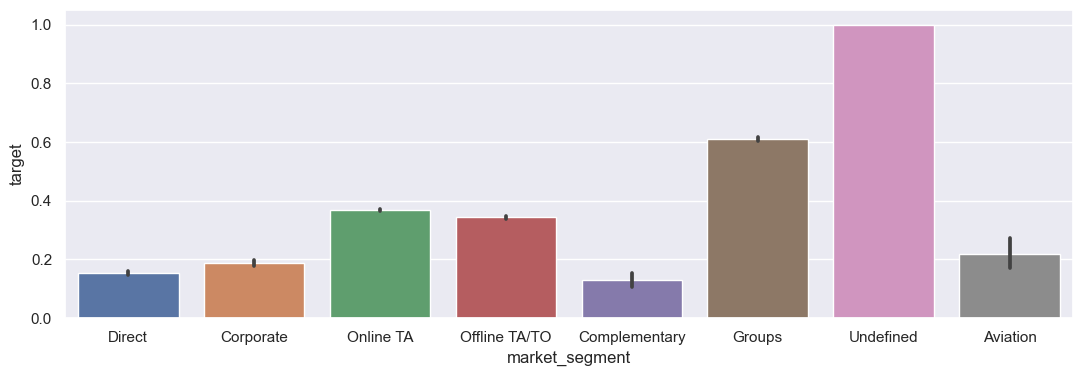

In [15]:
plt.figure(figsize=(13,4))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.barplot(data=df, x='market_segment', y= 'target', estimator=mean)
plt.show()

In [16]:
df.groupby('market_segment')['target'].count()

market_segment
Aviation           237
Complementary      743
Corporate         5295
Direct           12606
Groups           19811
Offline TA/TO    24219
Online TA        56477
Undefined            2
Name: target, dtype: int64

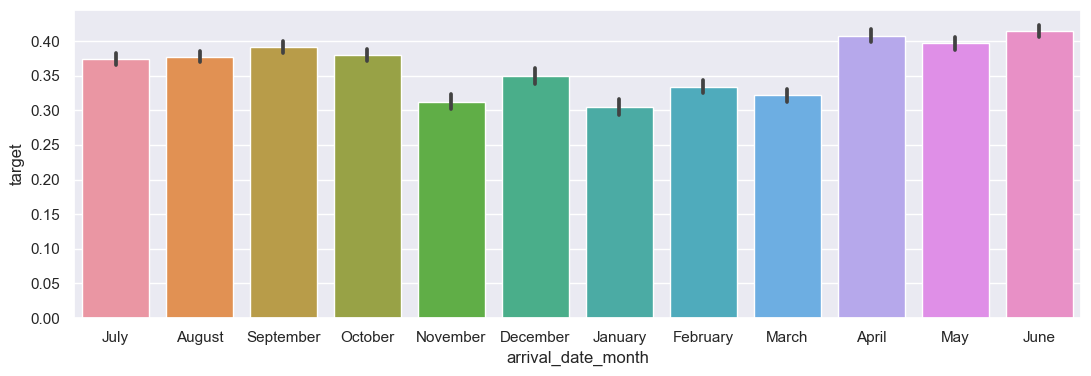

In [17]:
plt.figure(figsize=(13,4))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.barplot(data=df, x='arrival_date_month', y= 'target', estimator=mean)
plt.show()

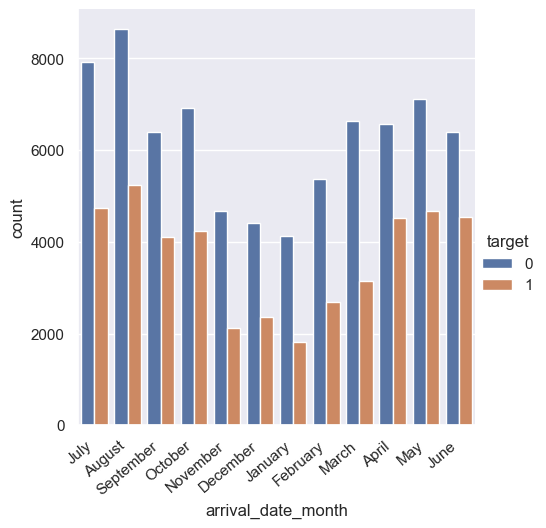

In [18]:
chart = sns.catplot(data=df, x='arrival_date_month', hue='target', kind='count')
chart.set_xticklabels(rotation=40, horizontalalignment='right')

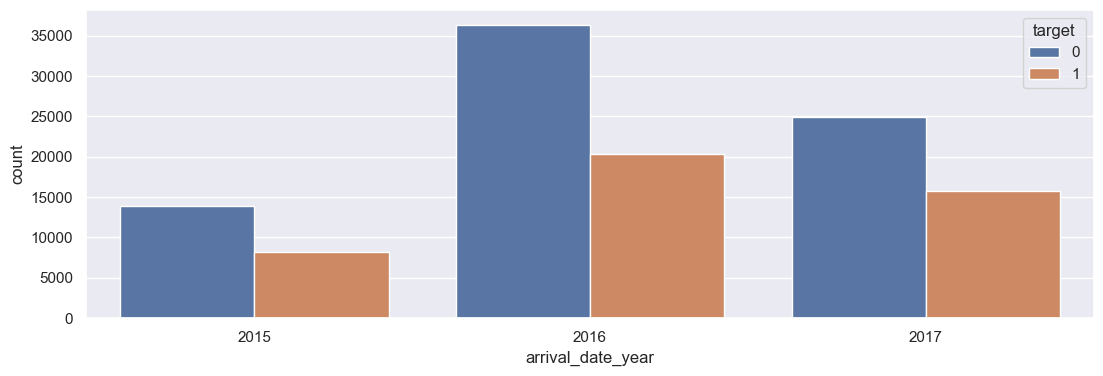

In [19]:
plt.figure(figsize=(13,4))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.countplot(data=df, x='arrival_date_year', hue='target')
plt.show()

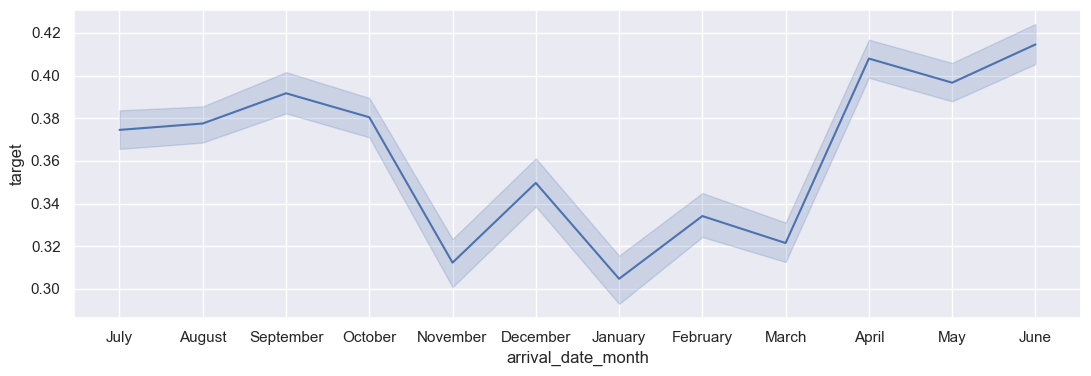

In [20]:
plt.figure(figsize=(13,4))
sns.lineplot(x="arrival_date_month", y="target", data=df)
plt.show()

In [21]:
df.groupby('arrival_date_month')['target'].mean()

arrival_date_month
April        0.407972
August       0.377531
December     0.349705
February     0.334160
January      0.304773
July         0.374536
June         0.414572
March        0.321523
May          0.396658
November     0.312334
October      0.380466
September    0.391702
Name: target, dtype: float64

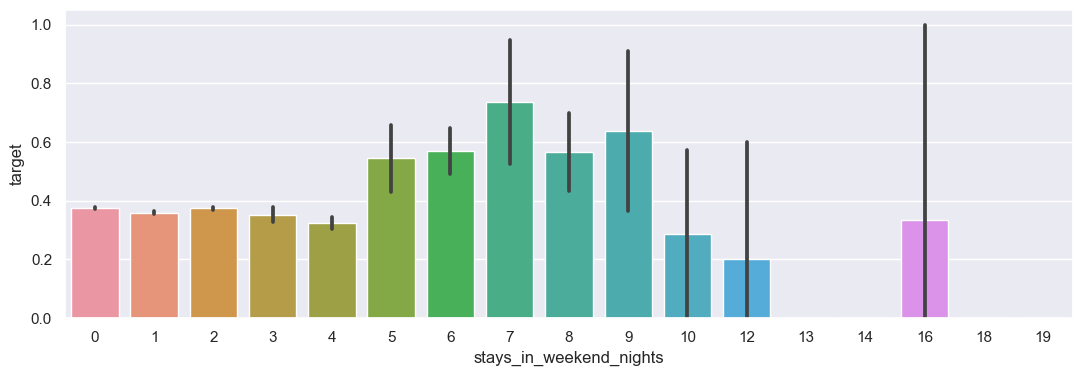

In [22]:
plt.figure(figsize=(13,4))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.barplot(data=df, x='stays_in_weekend_nights', y= 'target', estimator=mean)
plt.show()

In [23]:
df.groupby('stays_in_weekend_nights')['target'].mean()

stays_in_weekend_nights
0     0.375034
1     0.359401
2     0.374835
3     0.352661
4     0.322372
5     0.544304
6     0.568627
7     0.736842
8     0.566667
9     0.636364
10    0.285714
12    0.200000
13    0.000000
14    0.000000
16    0.333333
18    0.000000
19    0.000000
Name: target, dtype: float64

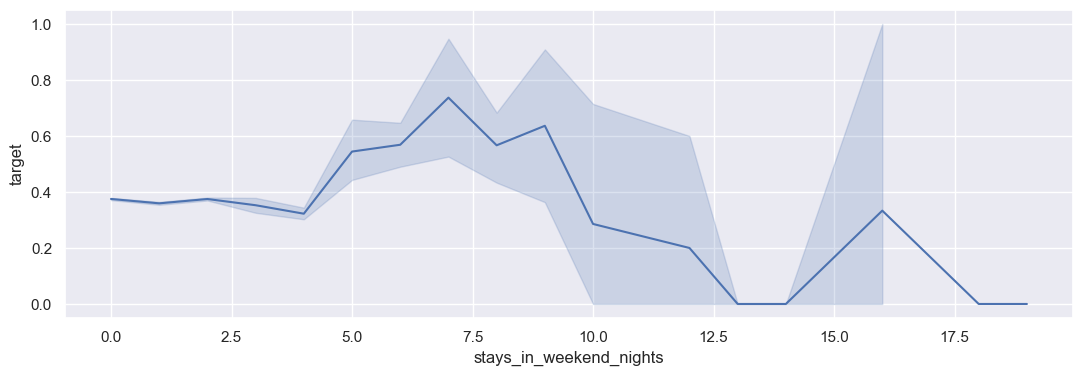

In [24]:
plt.figure(figsize=(13,4))
sns.lineplot(x="stays_in_weekend_nights", y="target", data=df)
plt.show()

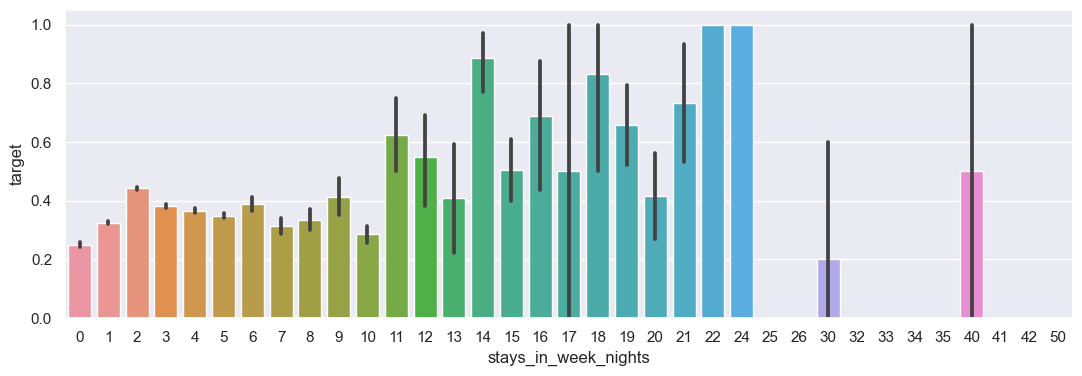

In [25]:
plt.figure(figsize=(13,4))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.barplot(data=df, x='stays_in_week_nights', y= 'target', estimator=mean)
plt.show()

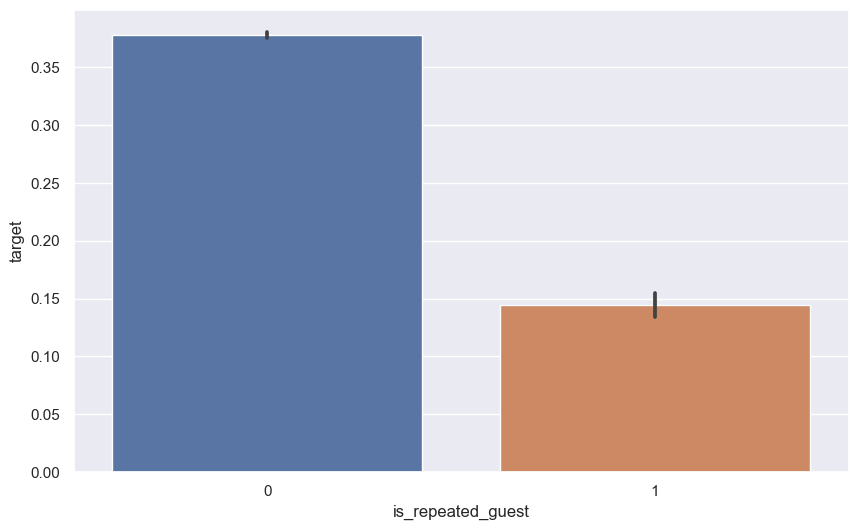

In [26]:
plt.figure(figsize=(10,6))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.barplot(data=df, x='is_repeated_guest', y= 'target', estimator=mean)
plt.show()

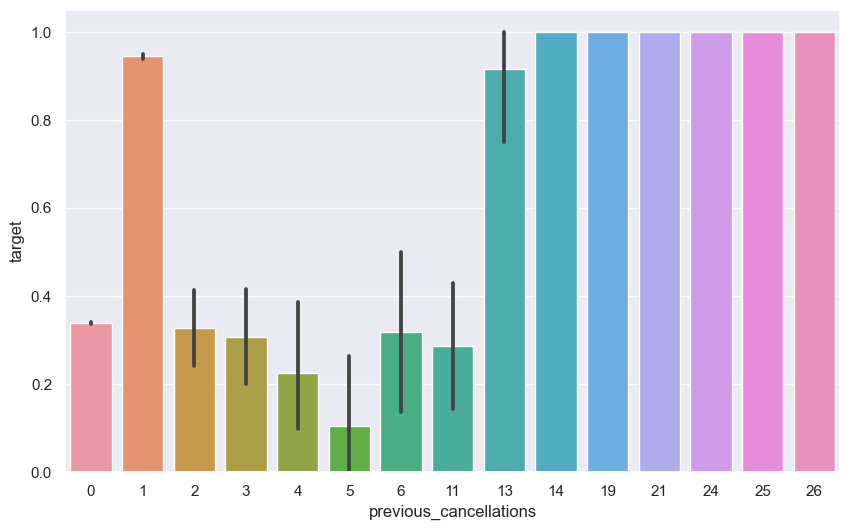

In [27]:
plt.figure(figsize=(10,6))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.barplot(data=df, x='previous_cancellations', y= 'target', estimator=mean)
plt.show()

In [28]:
df.groupby('previous_cancellations')['target'].count()

previous_cancellations
0     112906
1       6051
2        116
3         65
4         31
5         19
6         22
11        35
13        12
14        14
19        19
21         1
24        48
25        25
26        26
Name: target, dtype: int64

In [29]:
df['previous_cancel_ind'] = np.where(df['previous_cancellations'].isin([0]),0,1)
df.groupby('previous_cancel_ind')['target'].mean()

previous_cancel_ind
0    0.339061
1    0.916410
Name: target, dtype: float64

In [30]:
df.groupby('previous_bookings_not_canceled')['target'].count()

previous_bookings_not_canceled
0     115770
1       1542
2        580
3        333
4        229
       ...  
68         1
69         1
70         1
71         1
72         1
Name: target, Length: 73, dtype: int64

In [31]:
df.dtypes

hotel                              object
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
assigned_room_type                 object
booking_changes                     int64
deposit_type                       object
agent                             float64
company                           

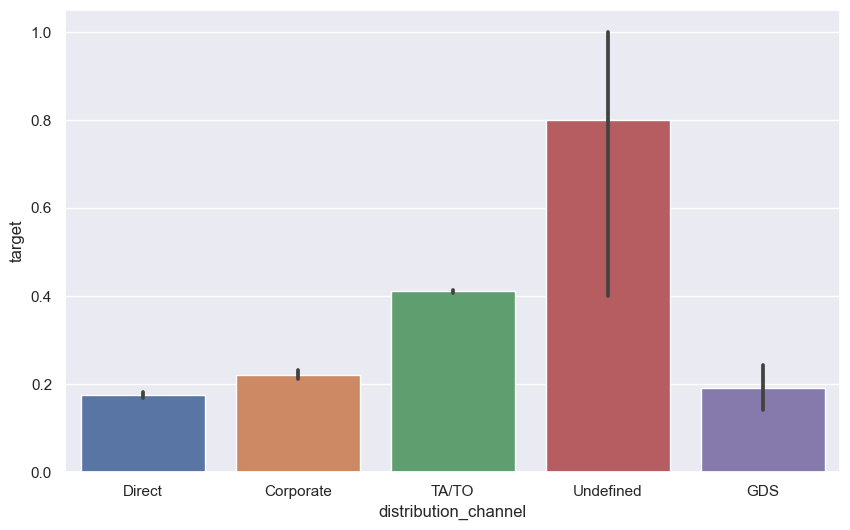

In [32]:
plt.figure(figsize=(10,6))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.barplot(data=df, x='distribution_channel', y= 'target', estimator=mean)
plt.show()

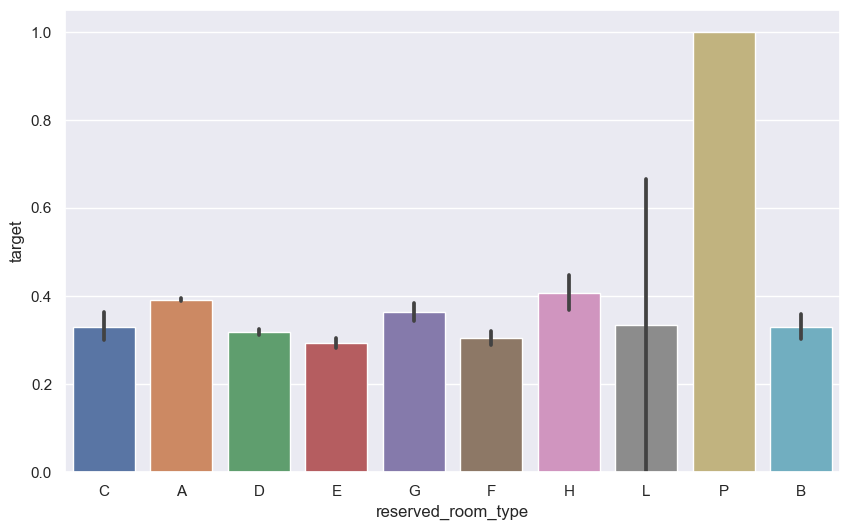

In [33]:
plt.figure(figsize=(10,6))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.barplot(data=df, x='reserved_room_type', y= 'target', estimator=mean)
plt.show()

In [34]:
df.groupby('reserved_room_type')['target'].mean()

reserved_room_type
A    0.391074
B    0.329159
C    0.330472
D    0.317796
E    0.292884
F    0.303763
G    0.364374
H    0.407654
L    0.333333
P    1.000000
Name: target, dtype: float64

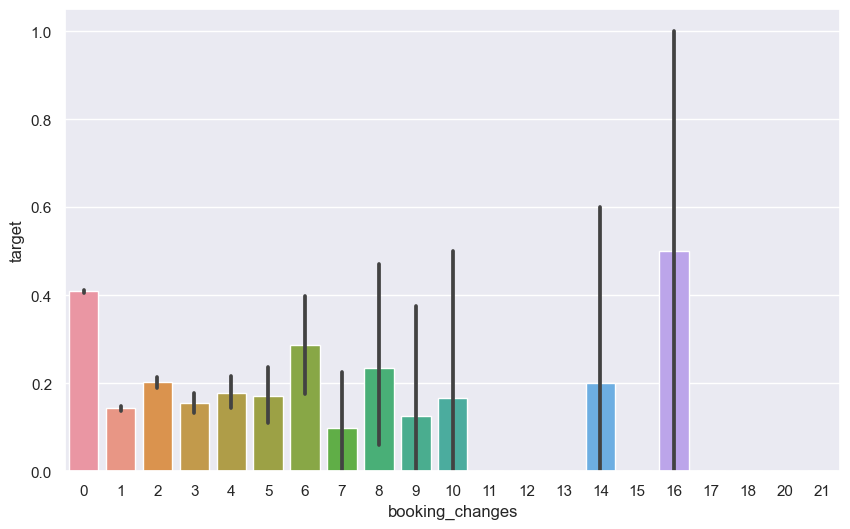

In [35]:
plt.figure(figsize=(10,6))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.barplot(data=df, x='booking_changes', y= 'target', estimator=mean)
plt.show()

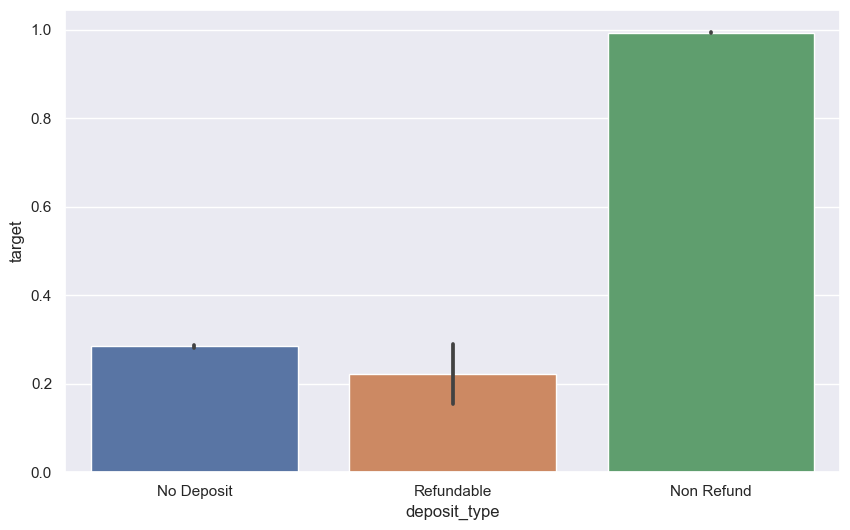

In [36]:
plt.figure(figsize=(10,6))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.barplot(data=df, x='deposit_type', y= 'target', estimator=mean)
plt.show()

In [37]:
df.groupby('deposit_type')['target'].mean()

deposit_type
No Deposit    0.283770
Non Refund    0.993624
Refundable    0.222222
Name: target, dtype: float64

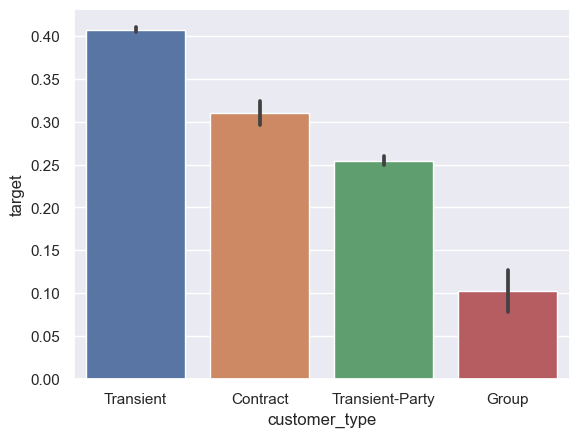

In [38]:
#plt.figure(figsize=(10,6))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.barplot(data=df, x='customer_type', y= 'target', estimator=mean)
plt.show()

In [39]:
df.groupby('customer_type')['target'].mean()

customer_type
Contract           0.309617
Group              0.102253
Transient          0.407463
Transient-Party    0.254299
Name: target, dtype: float64

In [40]:
df.groupby('customer_type')['target'].count()

customer_type
Contract            4076
Group                577
Transient          89613
Transient-Party    25124
Name: target, dtype: int64

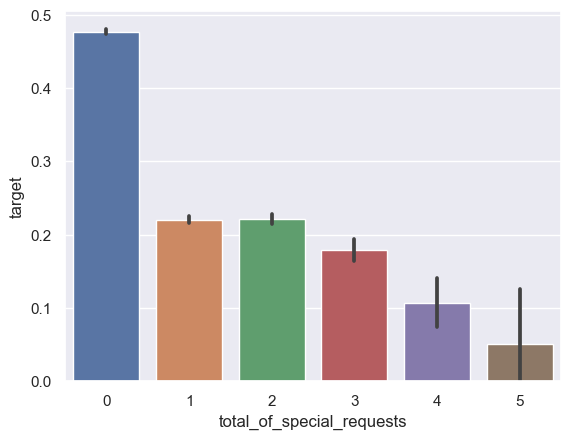

In [41]:
#plt.figure(figsize=(10,6))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.barplot(data=df, x='total_of_special_requests', y= 'target', estimator=mean)
plt.show()

In [42]:
df.groupby('total_of_special_requests')['target'].count()

total_of_special_requests
0    70318
1    33226
2    12969
3     2497
4      340
5       40
Name: target, dtype: int64

In [43]:
df.groupby('adr')['target'].count()

adr
-6.38          1
 0.00       1959
 0.26          1
 0.50          1
 1.00         15
            ... 
 450.00        1
 451.50        1
 508.00        1
 510.00        1
 5400.00       1
Name: target, Length: 8879, dtype: int64

# Multivariate Analysis

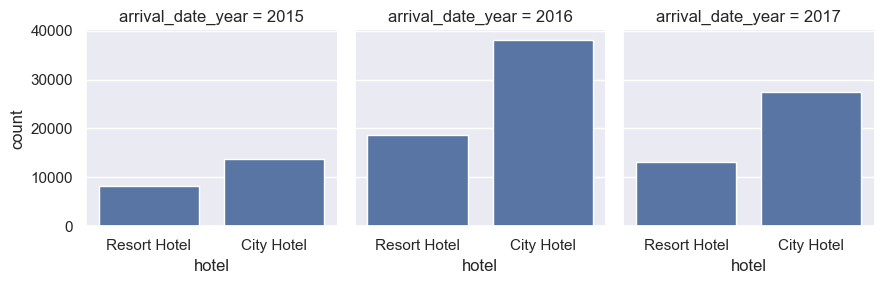

In [44]:
grid = sns.FacetGrid(df, col='arrival_date_year')
grid.map(sns.countplot, 'hotel')
plt.show()

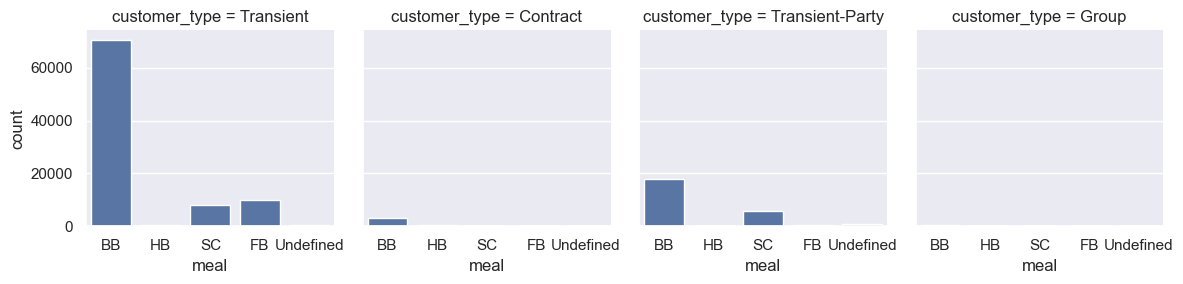

In [45]:
df['meal'].nunique(), df['customer_type'].nunique()
grid = sns.FacetGrid(df, col='customer_type')
grid.map(sns.countplot, 'meal')
plt.show()

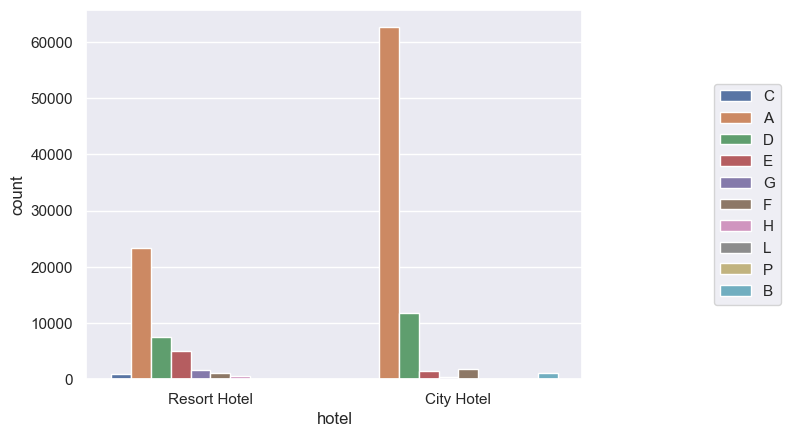

In [46]:
g = sns.countplot(data=df, x='hotel', hue='reserved_room_type')
g.legend(loc='center left', bbox_to_anchor=(1.25, 0.5), ncol=1)

In [47]:
df.pivot_table(columns='hotel', values=['stays_in_weekend_nights', 'stays_in_week_nights'], aggfunc=lambda x:x.sum())

hotel,City Hotel,Resort Hotel
stays_in_week_nights,173174,125337
stays_in_weekend_nights,63082,47664


In [48]:
df.pivot_table(columns='hotel', values='total_of_special_requests', aggfunc=lambda x:x.sum())

hotel,City Hotel,Resort Hotel
total_of_special_requests,43387,24828


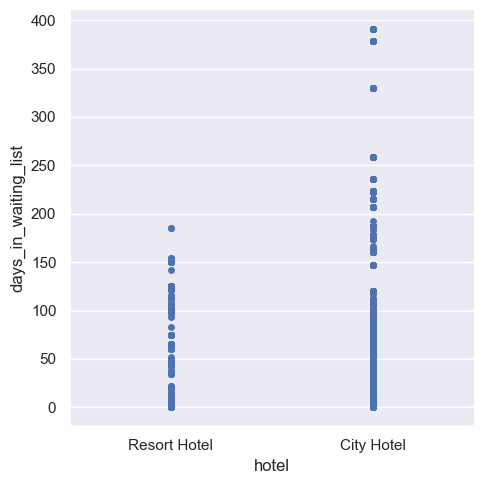

In [49]:
sns.catplot(data=df, x='hotel', y='days_in_waiting_list', jitter=False)
plt.show()

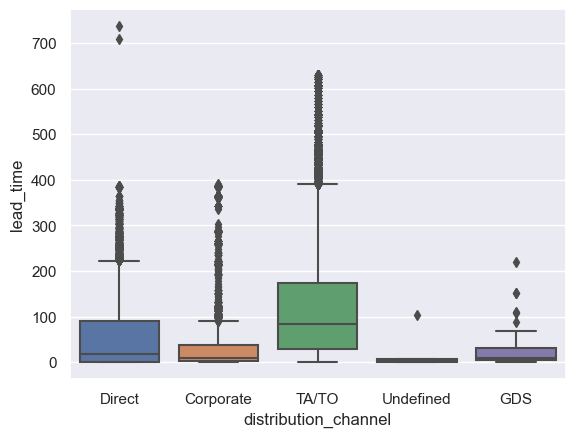

In [50]:
sns.boxplot(data=df, x='distribution_channel', y='lead_time')
plt.show()


# Feature Engineering

In [51]:
month_map = {'January':'01', 'February':'02', 'March':'03', 'April':'04', 'May':'05', 'June':'06', 'July':'07', 'August':'08', 'September':'09', 'October':'10', 'November':'11', 'December':'12'}
df.arrival_date_month = df.arrival_date_month.map(month_map).astype(int)

In [52]:
df['arrival_date'] = df['arrival_date_year'].astype(str)+'-'+df['arrival_date_month'].astype(str)+'-'+df['arrival_date_day_of_month'].astype(str)

In [53]:
def roomChange(row):
    if row['assigned_room_type'] == row['reserved_room_type']:
        return False
    else:
        return True

df['change_in_room'] = df.apply(roomChange, axis=1)

In [54]:
df['children'] = df['children'].fillna(0)
df['offspring'] = (df['children'] + df['babies']).astype(int)

In [55]:
df['total_bookings'] = df['previous_cancellations'] + df['previous_bookings_not_canceled']

In [56]:
df['country'].fillna(df['country'].mode()[0], inplace=True)
df['agent'].fillna(df['agent'].mode()[0], inplace=True)
df['company'].fillna(df['company'].mode()[0], inplace=True)

In [57]:
for i in range(len(df)):
    if df.loc[i, 'country'] == 'PRT':
        df.at[i, 'country'] = 1
    elif df.loc[i, 'country'] == 'GBR':
        df.at[i, 'country'] = 2
    else:
        df.at[i, 'country'] = 0

In [58]:
df['reservation_status_date'] = pd.to_datetime(df['reservation_status_date'])
df['arrival_date'] = pd.to_datetime(df['arrival_date'])

In [59]:
df['stay_duration'] = df['reservation_status_date'] - df['arrival_date']
df['stay_duration'] = df['stay_duration'] / np.timedelta64(1, 'D')
df['stay_duration'] = df['stay_duration'].astype(int)

In [60]:
for i in range(len(df)):
    if df.loc[i, 'stay_duration']<0:
        df.at[i, 'stay_duration'] = -1

In [61]:
lb = LabelEncoder()
cols = ['hotel', 'customer_type', 'deposit_type', 'change_in_room', 'market_segment', 'distribution_channel', 'country']
for item in cols:
    df[item] = lb.fit_transform(df[item])
df = pd.get_dummies(df, columns=cols)

In [62]:
df.drop(['meal', 'assigned_room_type', 'reserved_room_type', 'reservation_status', 'reservation_status_date', 'arrival_date'], axis=1, inplace=True)

<Figure size 1000x1800 with 0 Axes>

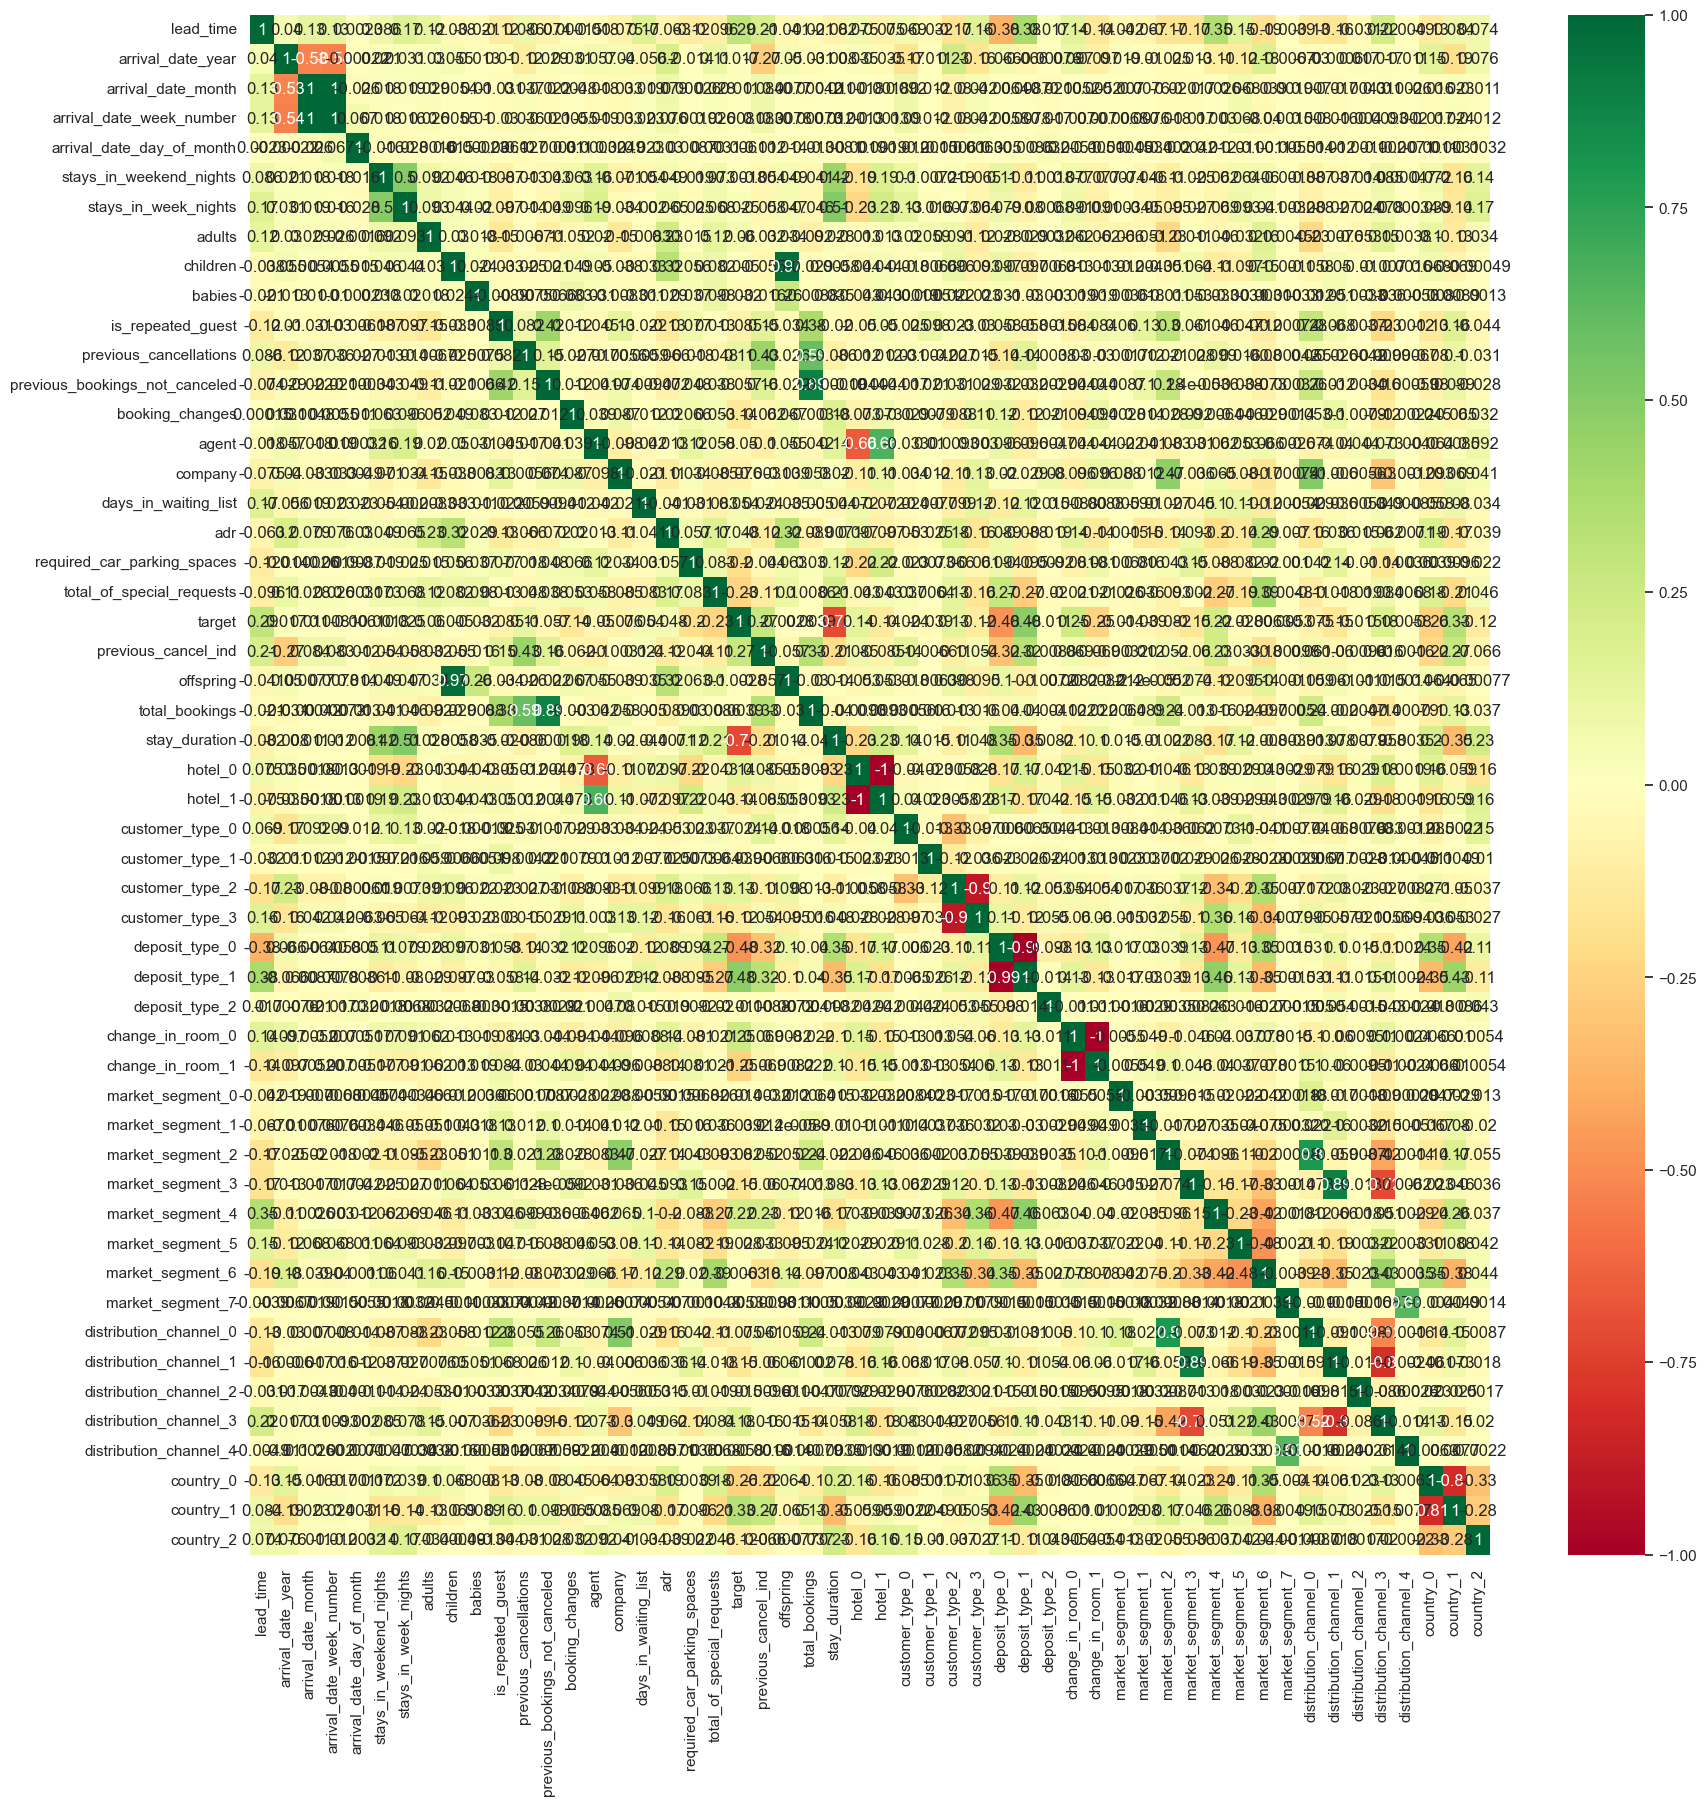

In [63]:
plt.figure(figsize=(10,18))
corrmat = df.corr()
top_corr_features = corrmat.index

plt.figure(figsize=(20,20))

#plot heat map
g=sns.heatmap(df[top_corr_features].corr(),annot=True,cmap="RdYlGn")

# Splitting the features

In [64]:
X = df.drop(['target'], axis=1)
y = df['target']

# Training the Model

In [65]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20)
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((95512, 51), (95512,), (23878, 51), (23878,))

# Common function for models

In [66]:
def classifier(train, test, estimator, param_grid):
    grid_search = GridSearchCV(estimator, param_grid, cv=5)
    grid_search.fit(train, y_train)
    print("Best parameters:", grid_search.best_params_)
    print("Best score:", grid_search.best_score_)
    print("Test score: {:.3f}".format(grid_search.score(test, y_test)))

def feature_selection(model):
    select_features = SelectFromModel(estimator=model, threshold='median')
    select_features.fit(X_train, y_train)
    X_train_select = select_features.transform(X_train)
    X_test_select = select_features.transform(X_test)
    return X_train_select, X_test_select

def run_model(model, model_feature, param_grid):
    print("Before feature selection:")
    classifier(X_train, X_test, model, param_grid)
    X_train_select, X_test_select = feature_selection(model_feature)
    print("After feature selection")
    classifier(X_train_select, X_test_select, model, param_grid)

# Model Building without feature selection

In [67]:
# Logistic Regression
logreg = LogisticRegression(max_iter=500).fit(X_train, y_train)
scores = cross_val_score(logreg, X_train, y_train, cv=5)
logreg_pred = logreg.predict(X_test)
print("Average cross validation score: {:.3f}".format(scores.mean()))
print("Test accuracy: {:.3f}".format(logreg.score(X_test, y_test)))
print("F1 score: {:.3f}".format(f1_score(y_test, logreg_pred)))
print(confusion_matrix(y_test, logreg_pred))
print(classification_report(y_test, logreg_pred))

Average cross validation score: 0.999
Test accuracy: 0.999
F1 score: 0.998
[[15027    13]
 [   14  8824]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     15040
           1       1.00      1.00      1.00      8838

    accuracy                           1.00     23878
   macro avg       1.00      1.00      1.00     23878
weighted avg       1.00      1.00      1.00     23878



In [68]:
#Decision Tree
tree = DecisionTreeClassifier(max_depth=1).fit(X_train, y_train)
scores = cross_val_score(tree, X_train, y_train, cv=5)
tree_pred = tree.predict(X_test)
print("Average cross validation score: {:.3f}".format(scores.mean()))
print("Test accuracy: {:.3f}".format(tree.score(X_test, y_test)))
print("F1 score: {:.3f}".format(f1_score(y_test, tree_pred)))
print(confusion_matrix(y_test, tree_pred))
print(classification_report(y_test, logreg_pred))

Average cross validation score: 0.994
Test accuracy: 0.994
F1 score: 0.991
[[14887   153]
 [    0  8838]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     15040
           1       1.00      1.00      1.00      8838

    accuracy                           1.00     23878
   macro avg       1.00      1.00      1.00     23878
weighted avg       1.00      1.00      1.00     23878



In [69]:
# Random Forest
param_grid = {'n_estimators':[50,75,100], 'max_depth':[1,2,5]}
run_model(RandomForestClassifier(), RandomForestClassifier(n_estimators=50, max_depth=2), param_grid)

Before feature selection:
Best parameters: {'max_depth': 5, 'n_estimators': 100}
Best score: 0.9971940768687662
Test score: 0.996
After feature selection
Best parameters: {'max_depth': 5, 'n_estimators': 75}
Best score: 0.9983457602308693
Test score: 0.998


In [70]:
#naive_bayes
gnb = GaussianNB()
gnb.fit(X_train, y_train)
scores = cross_val_score(gnb, X_train, y_train, cv=5)
gnb_pred = gnb.predict(X_test)
print("Average cross validation score: {:.3f}".format(scores.mean()))
print("Test accuracy: {:.3f}".format(gnb.score(X_test, y_test)))
print("F1 score: {:.3f}".format(f1_score(y_test, gnb_pred)))
print(confusion_matrix(y_test, gnb_pred))

Average cross validation score: 0.959
Test accuracy: 0.960
F1 score: 0.943
[[15008    32]
 [  920  7918]]


In [71]:
#Gradient Boosted Classifier
param_grid = {'max_depth':[1,2,5], 'learning_rate':[1,0.1,0.001]}
run_model(GradientBoostingClassifier(), GradientBoostingClassifier(learning_rate=0.001), param_grid)

Before feature selection:
Best parameters: {'learning_rate': 0.1, 'max_depth': 5}
Best score: 0.9995916767558995
Test score: 0.999
After feature selection
Best parameters: {'learning_rate': 0.1, 'max_depth': 5}
Best score: 0.9995916767558995
Test score: 0.999


# Feature Selection

[3.73893489e-02 1.49654956e-02 1.03129483e-02 1.24958678e-02
 1.15816437e-02 1.28705626e-02 1.95749279e-02 6.24495576e-03
 2.03695384e-03 4.27367050e-04 4.56158234e-03 2.63072579e-03
 1.54127683e-03 6.76619217e-03 1.41604689e-02 1.67635000e-03
 1.27468138e-03 1.49236882e-02 1.66246595e-02 2.92461696e-02
 2.91727400e-02 1.93691207e-03 2.15585204e-03 3.91224367e-01
 4.92739548e-03 3.85579447e-03 1.39146907e-03 3.06565758e-04
 1.24946463e-02 1.01927930e-02 6.99216755e-02 7.51732455e-02
 3.12374376e-04 1.90528925e-02 1.99591946e-02 1.65341776e-04
 2.89252197e-04 2.11477722e-03 4.71038785e-03 1.19612366e-02
 1.11701410e-02 1.97693433e-02 7.54702438e-06 1.88635994e-03
 5.35242648e-03 1.38830162e-04 9.23358601e-03 2.20105219e-05
 2.21880897e-02 4.17058177e-02 5.90106823e-03]


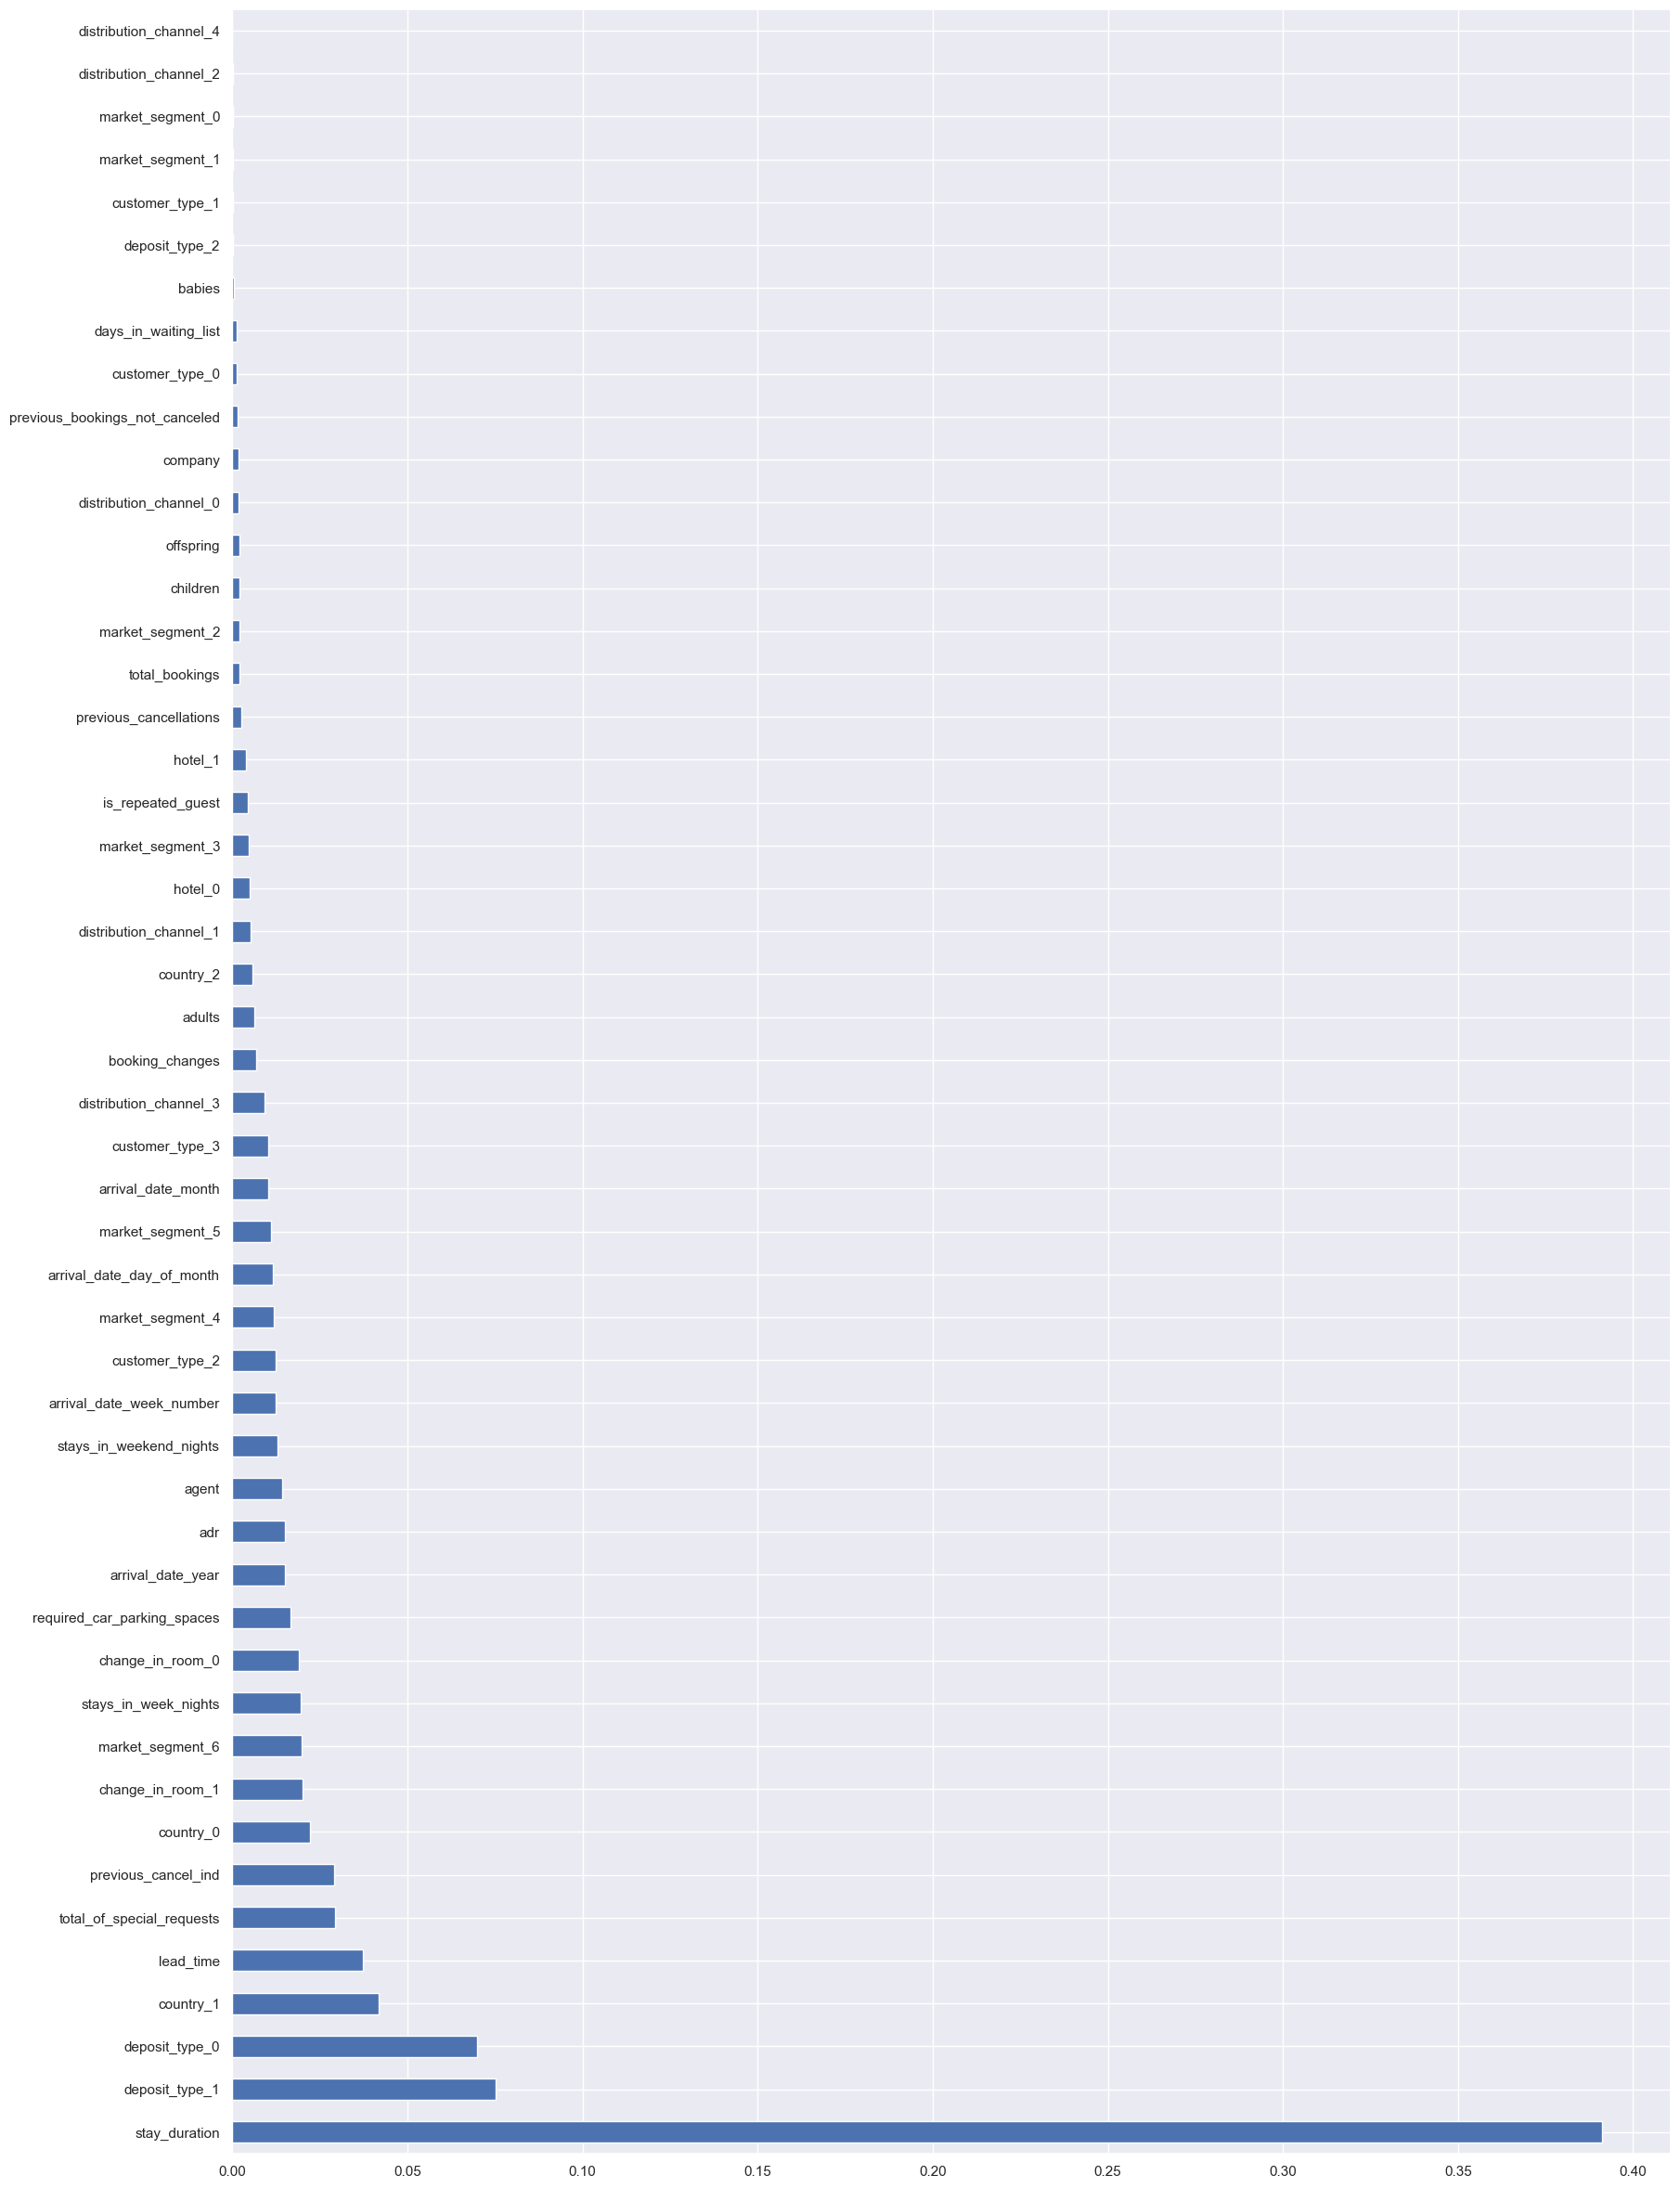

In [72]:
model = ExtraTreesClassifier()
model.fit(X,y)
print(model.feature_importances_) #use inbuilt class feature_importances of tree based classifiers

#plot graph of feature importances for better visualization
plt.figure(figsize=(20,30))
feat_importances = pd.Series(model.feature_importances_, index=X.columns)
feat_importances.nlargest(50).plot(kind='barh')
plt.show()

In [73]:
drop_feat = ['distribution_channel_4', 'distribution_channel_2', 'market_segment_0', 'deposit_type_2', 'customer_type_1',
            'market_segment_1', 'babies', 'days_in_waiting_list', 'previous_bookings_not_canceled', 'customer_type_0', 'company',
            'distribution_channel_0', 'offspring', 'total_bookings', 'children', 'market_segment_2', 'previous_cancellations',
            'hotel_0', 'hotel_1', 'is_repeated_guest','distribution_channel_1', 'market_segment_3','adults']

In [74]:
new_X = X.drop(columns=drop_feat, axis=1)


# Training model with feature selection

In [75]:
X_train, X_test, y_train, y_test = train_test_split(new_X, y, test_size=0.20)
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((95512, 28), (95512,), (23878, 28), (23878,))

# Model Building with feature selection

In [76]:
# Logistic Regression
logreg = LogisticRegression(max_iter=500).fit(X_train, y_train)
scores = cross_val_score(logreg, X_train, y_train, cv=5)
logreg_pred = logreg.predict(X_test)
print("Average cross validation score: {:.3f}".format(scores.mean()))
print("Test accuracy: {:.3f}".format(logreg.score(X_test, y_test)))
print("F1 score: {:.3f}".format(f1_score(y_test, logreg_pred)))
print(confusion_matrix(y_test, logreg_pred))
print(classification_report(y_test, logreg_pred))

Average cross validation score: 0.999
Test accuracy: 0.999
F1 score: 0.999
[[14939     8]
 [   16  8915]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     14947
           1       1.00      1.00      1.00      8931

    accuracy                           1.00     23878
   macro avg       1.00      1.00      1.00     23878
weighted avg       1.00      1.00      1.00     23878



In [77]:
#Decision Tree
tree = DecisionTreeClassifier(max_depth=1).fit(X_train, y_train)
scores = cross_val_score(tree, X_train, y_train, cv=5)
tree_pred = tree.predict(X_test)
print("Average cross validation score: {:.3f}".format(scores.mean()))
print("Test accuracy: {:.3f}".format(tree.score(X_test, y_test)))
print("F1 score: {:.3f}".format(f1_score(y_test, tree_pred)))
print(confusion_matrix(y_test, tree_pred))
print(classification_report(y_test, logreg_pred))

Average cross validation score: 0.994
Test accuracy: 0.995
F1 score: 0.994
[[14834   113]
 [    0  8931]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     14947
           1       1.00      1.00      1.00      8931

    accuracy                           1.00     23878
   macro avg       1.00      1.00      1.00     23878
weighted avg       1.00      1.00      1.00     23878



In [78]:
# Random Forest
param_grid = {'n_estimators':[50,75,100], 'max_depth':[1,2,5]}
run_model(RandomForestClassifier(), RandomForestClassifier(n_estimators=50, max_depth=2), param_grid)

Before feature selection:
Best parameters: {'max_depth': 5, 'n_estimators': 75}
Best score: 0.998439978595445
Test score: 0.999
After feature selection
Best parameters: {'max_depth': 5, 'n_estimators': 100}
Best score: 0.9947860002967452
Test score: 0.995


In [79]:
#naive_bayes
gnb = GaussianNB()
gnb.fit(X_train, y_train)
scores = cross_val_score(gnb, X_train, y_train, cv=5)
gnb_pred = gnb.predict(X_test)
print("Average cross validation score: {:.3f}".format(scores.mean()))
print("Test accuracy: {:.3f}".format(gnb.score(X_test, y_test)))
print("F1 score: {:.3f}".format(f1_score(y_test, gnb_pred)))
print(confusion_matrix(y_test, gnb_pred))

Average cross validation score: 0.945
Test accuracy: 0.946
F1 score: 0.922
[[14904    43]
 [ 1251  7680]]


In [80]:
#Gradient Boosted Classifier
param_grid = {'max_depth':[1,2,5], 'learning_rate':[1,0.1,0.001]}
run_model(GradientBoostingClassifier(), GradientBoostingClassifier(learning_rate=0.001), param_grid)

Before feature selection:
Best parameters: {'learning_rate': 0.1, 'max_depth': 2}
Best score: 0.9993927452549866
Test score: 1.000
After feature selection
Best parameters: {'learning_rate': 0.1, 'max_depth': 5}
Best score: 0.9994136849225838
Test score: 1.000


# Training Regression model to predict the number of booking nights for any new booking.

In [81]:
#In this model targer variable will be lead_times.
X = df.drop(['target'], axis=1)
y = df['target']

In [82]:
X['target'] = y

In [83]:
y = X['lead_time']

In [84]:
X = X.drop(['lead_time'], axis=1)

In [85]:
X_train, X_test, y_train, y_test = train_test_split(X, y,random_state = 0,test_size=0.25)

In [87]:
lr = LinearRegression()
print("R2:")
print(cross_val_score(lr, X_train.values, y_train.values, cv=4).mean())
print("MSE:")
print(-cross_val_score(lr, X_train.values, y_train.values, cv=4, scoring='neg_mean_squared_error').mean())

R2:
-119913038509120.78
MSE:
1.3568035366339868e+18


In [88]:
lr = lr.fit(X_train.values, y_train.values)
y_test_pred = lr.predict(X_test.values)
xmin= min(y_test.min(), y_test_pred.min() )-1
xmax= max(y_test.max(), y_test_pred.max() )+1

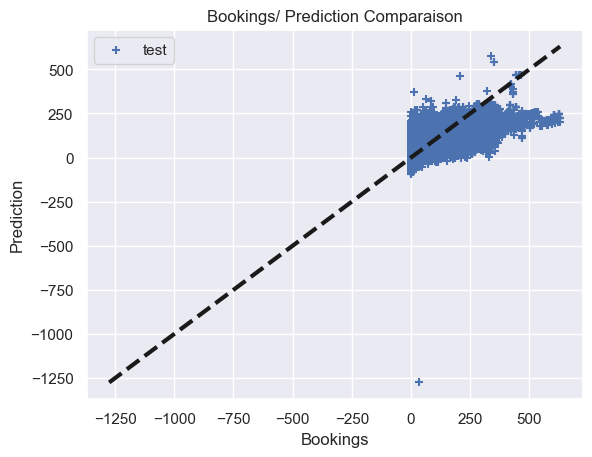

In [89]:
fig = plt.figure(1)
plt.scatter(y_test,y_test_pred, marker='+', label='test')
plt.plot([xmin,xmax], [xmin,xmax], lw=3, color='k', ls='--') ## droite separatrice d'equation x2=x1

plt.xlabel('Bookings')
plt.ylabel('Prediction') 
plt.title('Bookings/ Prediction Comparaison')
plt.legend()
plt.show()

In [91]:
model_2 = RandomForestRegressor()
print("R2:")
print(cross_val_score(model_2, X_train.values, y_train.values, cv=4).mean())
print("MSE:")
print(-cross_val_score(model_2, X_train.values, y_train.values, cv=4, scoring='neg_mean_squared_error').mean())

R2:
0.8424586918504555
MSE:
1796.4956535616946


In [ ]:
model_2 = model_2.fit(X_train.values, y_train.values)
y_test_pred = model_2.predict(X_test.values)
xmin= min(y_test.min(), y_test_pred.min() )-1
xmax= max(y_test.max(), y_test_pred.max() )+1

In [ ]:
fig = plt.figure(1)
plt.scatter(y_test,y_test_pred, marker='+', label='test')
plt.plot([xmin,xmax], [xmin,xmax], lw=3, color='k', ls='--') ## droite separatrice d'equation x2=x1

plt.xlabel('Bookings')
plt.ylabel('Prediction') 
plt.title('Bookings/ Prediction Comparaison')
plt.legend()
plt.show()

In [ ]:
model_3 = GradientBoostingRegressor()
print("R2:")
print(cross_val_score(model_3, X_train.values, y_train.values, cv=4).mean())
print("MSE:")
print(-cross_val_score(model_3, X_train.values, y_train.values, cv=4, scoring='neg_mean_squared_error').mean())

In [ ]:
model_3 = model_3.fit(X_train.values, y_train.values)
y_test_pred = model_3.predict(X_test.values)
xmin= min(y_test.min(), y_test_pred.min() )-1
xmax= max(y_test.max(), y_test_pred.max() )+1

In [ ]:
fig = plt.figure(1)
plt.scatter(y_test,y_test_pred, marker='+', label='test')
plt.plot([xmin,xmax], [xmin,xmax], lw=3, color='k', ls='--') ## droite separatrice d'equation x2=x1

plt.xlabel()
plt.ylabel() 
plt.title()
plt.legend()
plt.savefig('XGB.png')

In [ ]:
#from sklearn.model_selection import GridSearchCV
# Create the parameter grid based on the results of random search 
#param_grid = {

    'n_estimators': [100, 150, 200, 400, 500]
#}
# Create a based model
#rf = RandomForestRegressor()
# Instantiate the grid search model
#grid_search = GridSearchCV(estimator = rf, param_grid = param_grid, 
                          cv = cv, n_jobs = -1, verbose = 2)

In [ ]:
#grid_search.fit(X_train.values, y_train.values)
#best_grid = grid_search.best_estimator_